# From linear classification to neural networks

**Lab 5 · Building and fitting a neural network**

In Labs 3 and 4, you fitted linear predictors and classifiers. Here we supply
the familiar affine classifier on a new dataset. **You will implement a neural
network, use PyTorch to calculate its derivatives, adapt gradient descent, and
interpret the supplied plots.**

We begin by creating a noisy dataset based on the XOR example from the lecture
and examining how poorly a linear classifier fits it. We then try the architecture
introduced in the lecture, a neural network with a single hidden layer of two
neurons, and investigate how different initialisations affect optimisation.
Finally, we explore two other architectures: one with a single hidden layer of
100 neurons, and one with two hidden layers of 5 and 7 neurons, respectively.

Use **Google Colab** and work from top to bottom. In each **YOUR CODE** gap,
replace `raise NotImplementedError(...)` with your code before opening
**Show answer**. Worked answers contain the complete code for their exercise
cell. All plotting code is supplied.

Use the parameter, function and result names requested in the exercises.
We build on Python and tensor operations from Labs 1–4, explaining new
operations when you need them.

## 1. Generate and visualise the data

We generate **100 observations**, arranged in four Gaussian clouds. Each cloud has 25 observations, with independent coordinate noise of standard deviation $0.225$.

| Cloud centre | Class | Observations |
|---|---:|---:|
| $(0,0)$ | 0 | 25 |
| $(1,1)$ | 0 | 25 |
| $(0,1)$ | 1 | 25 |
| $(1,0)$ | 1 | 25 |

The centres form the lecture's XOR arrangement: diagonally opposite clouds share a label. Each observation keeps the label of its generating cloud while its coordinates are perturbed. Blue circles show class 0 and orange triangles show class 1, as in Lab 4.

The tensor `X` contains the two input coordinates and has shape `(N, 2)`. The labels in `y` have shape `(N, 1)`. Run the supplied cell to create and visualise the data.

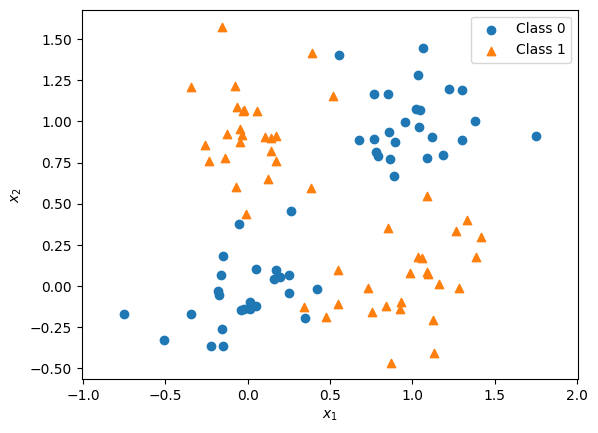

In [5]:
import torch as t
import matplotlib.pyplot as plt
t.manual_seed(1)  # Fix the random seed for this notebook.

N = 100
# Four Gaussian clouds in an XOR arrangement: 25 observations per cloud.
# spread is the standard deviation of each coordinate, not a variance.
spread = 0.225
x_class_0 = t.cat([
    t.randn(N // 4, 2) * spread + t.tensor([0.0, 0.0]),
    t.randn(N // 4, 2) * spread + t.tensor([ 1.0,  1.0])
], 0)
x_class_1 = t.cat([
    t.randn(N // 4, 2) * spread + t.tensor([0.0, 1.0]),
    t.randn(N // 4, 2) * spread + t.tensor([1.0, 0.0])
], 0)
X = t.cat([x_class_0, x_class_1], 0)              # Shape: (100, 2).
y = t.cat([t.zeros(N // 2, 1), t.ones(N // 2, 1)], 0)  # Shape: (100, 1).

# Show observed classes using the same colours and markers as in Lab 4.
plt.figure()
plt.scatter(x=x_class_0[:, 0], y=x_class_0[:, 1], color='tab:blue', label='Class 0')
plt.scatter(x=x_class_1[:, 0], y=x_class_1[:, 1], color='tab:orange', marker='^', label='Class 1')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.axis('equal')
plt.legend()
plt.show()

Run the following supplied cell to prepare the plots.

In [6]:
#@title Supplied plotting helpers — run this cell once; no changes are needed.
import math

restart_curve_colors = ['#666666', '#0072B2', '#E69F00', '#009E73', '#AA4499', '#D55E00']

# This grid is only for drawing pictures; it adds no fitting observations.
x1_limits = (X[:, 0].min().item() - 0.25, X[:, 0].max().item() + 0.25)
x2_limits = (X[:, 1].min().item() - 0.25, X[:, 1].max().item() + 0.25)
x1_grid, x2_grid = t.meshgrid(t.linspace(*x1_limits, 250),
                            t.linspace(*x2_limits, 250), indexing='xy')
X_grid = t.stack([x1_grid, x2_grid], dim=-1).reshape(-1, 2)

def save_boundary(scores):
    return scores.reshape(x1_grid.shape).detach()

def save_affine_boundary(theta):
    return (theta[0] + X_grid @ theta[1:]).reshape(x1_grid.shape)

def plot_affine_curves(losses, mistakes):
    updates = range(len(losses))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    axes[0].plot(updates, losses, color='0.35')
    axes[0].set(title='Affine model: empirical logistic loss', ylabel='Summed empirical logistic loss', ylim=(0, 75))
    axes[1].plot(updates, [value / math.log(2) for value in losses],
                 color='tab:purple', label=r'Empirical logistic loss / $\log 2$')
    axes[1].plot(updates, mistakes, color='tab:green', label='Mistakes')
    axes[1].set(title='Affine model\nEmpirical logistic loss and mistakes', ylabel='Value', ylim=(0, 110))
    axes[1].legend()
    for ax in axes:
        ax.set_xlabel('Completed updates')
        ax.grid(alpha=0.2)
    plt.show()

def plot_affine_boundaries(checkpoints):
    x1_line = t.tensor(x1_limits)
    fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)
    ax.scatter(x_class_0[:, 0], x_class_0[:, 1], color='tab:blue', label='Class 0')
    ax.scatter(x_class_1[:, 0], x_class_1[:, 1], color='tab:orange', marker='^', label='Class 1')
    for (step, theta), style in zip(checkpoints.items(), (':', '--', '-.', '-')):
        b, w1, w2 = theta[:, 0]
        x2_line = -(b + w1 * x1_line) / w2
        ax.plot(x1_line, x2_line, color='black', linestyle=style,
                label=f'After {step} update' + ('s' if step != 1 else ''))
    ax.set(xlim=x1_limits, ylim=x2_limits, xlabel='$x_1$', ylabel='$x_2$',
           title='Affine decision boundaries')
    ax.set_aspect('equal')
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.show()

def plot_first_comparison(affine_losses, affine_mistakes, network_losses, network_mistakes):
    updates = range(len(network_losses))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    axes[0].plot(updates, affine_losses, '--', color='0.4', label='Affine score')
    axes[0].plot(updates, network_losses, color='tab:purple', label='Two-neuron network')
    axes[0].set(title='Empirical logistic loss', ylabel='Summed empirical logistic loss')
    for ax, losses, mistakes, title in zip(
            axes[1:], [affine_losses, network_losses], [affine_mistakes, network_mistakes],
            ['Affine model\nEmpirical logistic loss and mistakes', 'Two-neuron network\nEmpirical logistic loss and mistakes']):
        ax.plot(updates, t.tensor(losses) / math.log(2), color='tab:purple', label=r'Empirical logistic loss / $\log 2$')
        ax.plot(updates, mistakes, color='tab:green', label='Mistakes')
        ax.set(title=title, ylabel='Value', ylim=(0, 1.1 * max(100, max(losses) / math.log(2))))
    for ax in axes:
        ax.set_xlabel('Completed updates')
        ax.grid(alpha=0.2)
        ax.legend()
    plt.show()

def plot_network_curves(labels, loss_histories, error_histories, colors=None):
    assert len(labels) == len(loss_histories) == len(error_histories)
    assert colors is None or len(colors) == len(labels)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    styles = ['--', '-'] if len(labels) == 2 else [':', '--', '-', '-.', (0, (5, 1, 1, 1, 1, 1)), (0, (7, 3))]
    for index, (label, losses, mistakes) in enumerate(zip(labels, loss_histories, error_histories)):
        updates = range(len(losses))
        style = '-' if colors is not None else styles[index % len(styles)]
        axes[0].plot(updates, losses, linestyle=style,
                     color=colors[index] if colors is not None else 'tab:purple', label=label)
        axes[1].plot(updates, mistakes, linestyle=style,
                     color=colors[index] if colors is not None else 'tab:green', label=label)
    axes[0].set(title='Empirical logistic loss', ylabel='Summed empirical logistic loss (log scale)', yscale='log')
    axes[1].set(title='Classification mistakes', ylabel='Mistakes')
    for ax in axes:
        ax.set_xlabel('Completed updates')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8 if len(labels) > 3 else 10)
    plt.show()

def draw_boundary(ax, score_grid, title):
    classes = (score_grid > 0).to(t.float32)
    ax.contourf(x1_grid, x2_grid, classes,
                levels=[-0.5, 0.5, 1.5], colors=['#edf3fb', '#fff1e9'])
    ax.contour(x1_grid, x2_grid, score_grid, levels=[0], colors='black', linewidths=1)
    class_0 = y[:, 0] == 0
    class_1 = y[:, 0] == 1
    ax.scatter(X[class_0, 0], X[class_0, 1], color='tab:blue', s=18, label='Class 0')
    ax.scatter(X[class_1, 0], X[class_1, 1], color='tab:orange', marker='^', s=20, label='Class 1')
    ax.set(xlim=x1_limits, ylim=x2_limits, xlabel='$x_1$', ylabel='$x_2$', title=title)
    ax.set_aspect('equal')

def plot_boundaries(score_grids, labels, mistake_counts):
    assert len(score_grids) == len(labels) == len(mistake_counts)
    width = {2: 10, 3: 13, 4: 15}[len(score_grids)]
    fig, axes = plt.subplots(1, len(score_grids), figsize=(width, 4), constrained_layout=True)
    for ax, scores, label, mistakes in zip(axes, score_grids, labels, mistake_counts):
        draw_boundary(ax, scores, f'{label}\nMistakes: {mistakes}')
    axes[0].legend(loc='upper left', fontsize=8)
    plt.show()

def plot_lecture_comparison(original_scores, original_loss, original_mistakes, lecture_network):
    scores = lecture_network(X)
    lecture_loss = loss_from_scores(scores).item()
    lecture_mistakes = mistakes_from_scores(scores)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    draw_boundary(axes[0], original_scores,
                  f'Original fitted two-neuron network\nEmpirical logistic loss: {original_loss:.3f}\nMistakes: {original_mistakes}')
    draw_boundary(axes[1], save_boundary(lecture_network(X_grid)),
                  f'Two-neuron network from the lecture\nEmpirical logistic loss: {lecture_loss:.3f}\nMistakes: {lecture_mistakes}')
    axes[0].legend(loc='upper left', fontsize=8)
    plt.show()

def plot_restart_curves(seeds, losses, mistakes, original_losses, original_mistakes, selected_seed):
    labels = ['Original initialisation'] + [
        f'Seed {seed}' + (' (selected)' if seed == selected_seed else '')
        for seed in seeds]
    plot_network_curves(labels, [original_losses] + [losses[seed] for seed in seeds],
                        [original_mistakes] + [mistakes[seed] for seed in seeds],
                        colors=restart_curve_colors)

def plot_restart_boundaries(seeds, grid_scores, losses, mistakes,
                            original_scores, original_loss, original_mistakes, selected_seed):
    assert len(seeds) == 5
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
    panels = axes.ravel()
    draw_boundary(panels[0], original_scores,
                  f'Original initialisation\nEmpirical logistic loss: {original_loss:.3f}\nMistakes: {original_mistakes}')
    for ax, seed in zip(panels[1:], seeds):
        label = f'Seed {seed}' + (' — selected' if seed == selected_seed else '')
        draw_boundary(ax, grid_scores[seed],
                      f'{label}\nEmpirical logistic loss: {losses[seed][-1]:.3f}\nMistakes: {mistakes[seed][-1]}')
    panels[0].legend(loc='upper left', fontsize=8)
    plt.show()

def plot_wide_curves(seeds, losses, mistakes, selected_seed):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
    for seed, color in zip(seeds, restart_curve_colors[1:]):
        label = f'Seed {seed}' + (' (selected)' if seed == selected_seed else '')
        updates = range(len(losses[seed]))
        axes[0].plot(updates, losses[seed], color=color, linestyle='-', label=label)
        axes[1].plot(updates[100:], losses[seed][100:], color=color, linestyle='-', label=label)
        axes[2].plot(updates, mistakes[seed], color=color, linestyle='-', label=label)
    axes[0].set(title='Empirical logistic loss', ylabel='Summed empirical logistic loss')
    axes[1].set(title='Empirical logistic loss: updates 100–10000',
                ylabel='Summed empirical logistic loss',
                xlim=(100, len(losses[seeds[0]]) - 1),
                ylim=(0, 1.05 * max(max(losses[seed][100:]) for seed in seeds)))
    axes[2].set(title='Classification mistakes', ylabel='Mistakes')
    for ax in axes:
        ax.set_xlabel('Completed updates')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    plt.show()

def plot_wide_boundaries(seeds, grid_scores, losses, mistakes, selected_seed):
    assert len(seeds) == 5
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
    panels = axes.ravel()
    for ax, seed in zip(panels, seeds):
        label = f'100 neurons: seed {seed}' + (' (selected)' if seed == selected_seed else '')
        draw_boundary(ax, grid_scores[seed],
                      f'{label}\nEmpirical logistic loss: {losses[seed][-1]:.3f}\nMistakes: {mistakes[seed][-1]}')
    panels[-1].set_axis_off()
    panels[0].legend(loc='upper left', fontsize=8)
    plt.show()

## 2. Reuse the linear classifier from Lab 4

Look at the four clouds. **Could a single straight decision boundary separate the four centres according to their labels?** Keep your prediction in mind while running the model.

The supplied code reuses Lab 4's affine model, empirical logistic loss, gradient and mistake count.

As in Lab 4, we include the intercept using a column of ones. Here that design matrix is called `X_affine`, while `X` keeps the original coordinates for the later network.

The coefficient column contains $(b,w_1,w_2)$, and the scores are `X_affine @ theta`. The predicted label is 1 when the sigmoid of the score is greater than 0.5, and 0 otherwise, including at equality. This is equivalent to testing whether the score is strictly positive.

In [7]:
# Supplied: the completed functions from Lab 4, with affine-specific names.
X_affine = t.cat([t.ones(N, 1), X], dim=1)  # Shape (N, 3), including the intercept.

def affine_loss(theta):
    scores = X_affine @ theta
    return -(y * t.nn.functional.logsigmoid(scores)
             + (1 - y) * t.nn.functional.logsigmoid(-scores)).sum()

def affine_grad(theta):
    scores = X_affine @ theta
    probabilities = t.sigmoid(scores)
    return X_affine.mT @ (probabilities - y)

def affine_mistakes(theta):
    probabilities = t.sigmoid(X_affine @ theta)
    predicted_labels = (probabilities > 0.5).to(y.dtype)
    return int((predicted_labels != y).sum().item())

### 2.1. Run gradient descent

Run the supplied update loop. We use Lab 4's zero initialisation and learning
rate `0.01`, now allowing **10,000 updates**. Every update uses the full dataset.
Compare the empirical logistic loss and mistake count before and after fitting.

In [8]:
affine_theta = t.zeros(3, 1)
affine_learning_rate = 0.01
num_updates = 10000
affine_loss_history = [affine_loss(affine_theta).item()]
affine_error_history = [affine_mistakes(affine_theta)]
affine_checkpoints = {}

for step in range(1, num_updates + 1):
    affine_theta = affine_theta - affine_learning_rate * affine_grad(affine_theta)
    affine_loss_history.append(affine_loss(affine_theta).item())
    affine_error_history.append(affine_mistakes(affine_theta))

    # Supplied: save this tensor; each later update creates a new one.
    if step in (1, 10, 100, num_updates):
        affine_checkpoints[step] = affine_theta

print('Updates   Empirical logistic loss   Mistakes')
for step in (0, 1, 10, 100, num_updates):
    print(f'{step:7d}   {affine_loss_history[step]:23.6f}   {affine_error_history[step]:8d}')

Updates   Empirical logistic loss   Mistakes
      0                 69.314713         50
      1                 69.313766         36
     10                 69.310265         39
    100                 69.308266         47
  10000                 69.308266         47


### 2.2. Inspect the curves and the boundaries

Run the supplied plotting cells. These are the same quantities we examined in Lab 4:

- the summed empirical logistic loss;
- the empirical logistic loss divided by $\log 2$, alongside the number of mistakes;
- the decision boundaries at successive updates.

The division by $\log 2$ is only for display: **the updates use the original, unscaled empirical logistic loss**. Each mistake contributes at least $\log 2$ to that empirical logistic loss, so the scaled empirical logistic loss bounds the mistake count from above.

The affine decision boundary satisfies $b+w_1x_1+w_2x_2=0$.

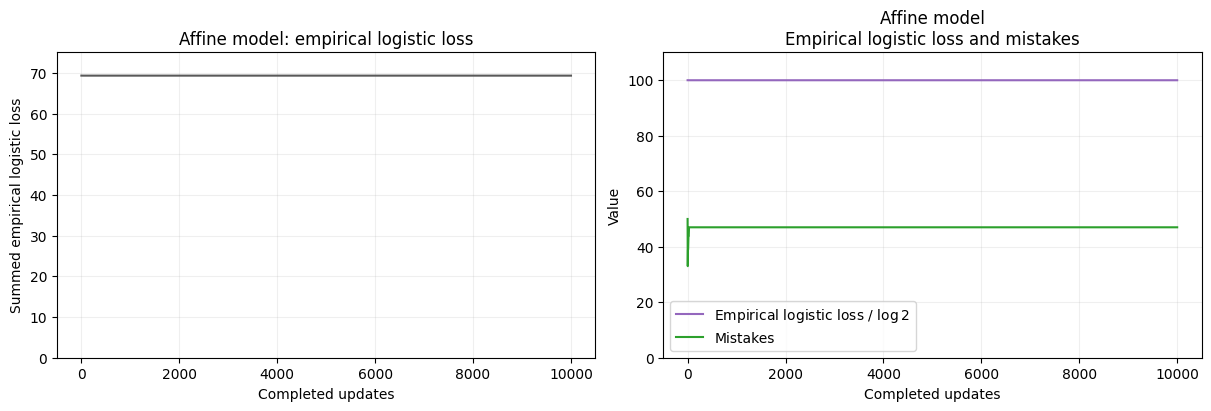

In [9]:
# Supplied: the affine empirical logistic loss and mistake curves.
plot_affine_curves(affine_loss_history, affine_error_history)

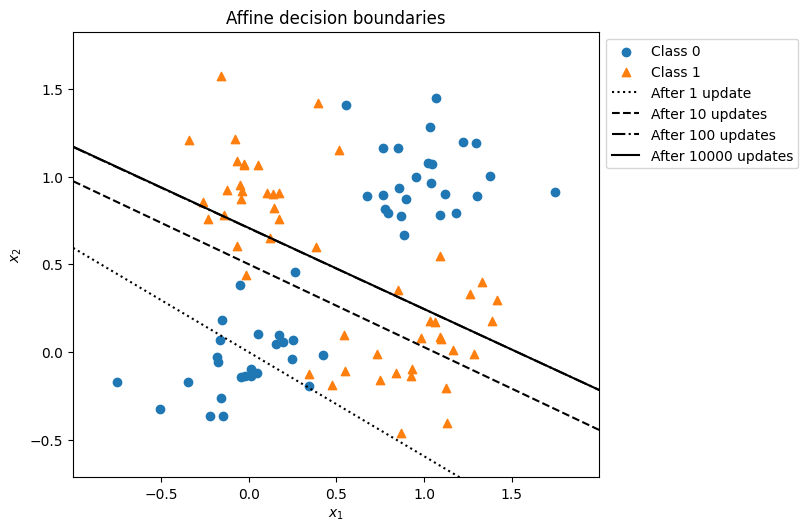

In [10]:
# Supplied: draw the saved affine boundaries and keep its final picture.
plot_affine_boundaries(affine_checkpoints)
affine_grid_scores = save_affine_boundary(affine_theta)

### Pause and interpret: what has gradient descent achieved?

1. Use the printed values to quantify the change in empirical logistic loss. Why does its curve appear almost flat even though the mistake count changes? Has the affine model fitted the observations well?
2. What happens to the boundary between updates 1, 100 and 10,000? Could more updates turn it into a boundary with several segments?
3. Why do the empirical logistic loss and the number of mistakes not necessarily decrease together?

Write down your answers before opening the explanation.

1- because it is affine with ax + b and therefore it will be flalt. It fitted the observation but it didn't classify well.

2- It suited the data more, it is just that it linear with ax + b so no several segments.

3- I think it fits the data better but doesn't guarante a decrease in the count of mistakes

The main takeaway: Gradient descent can successfully minimize logistic loss without achieving good classification accuracy. For XOR, the fundamental issue is not the training algorithm — it's that a linear decision boundary is insufficient.

<details>
<summary>Show answer — interpreting the affine fit</summary>

**1. The empirical logistic loss decreases very little.** It falls from
approximately $69.3147$ to $69.3083$, a decrease of about $0.00645$, so its curve
looks almost flat. The mistake count starts at 50, falls to 33 after 3 updates
(remaining there after update 4), then rises to 47 by update 100.

Initially, every coefficient and score is zero, so each predicted probability
is $1/2$. The summed empirical logistic loss is therefore $N\log 2\approx69.3147$;
dividing by $\log 2$ makes the purple curve start at 100. For this nearly symmetric
XOR sample, the fitted probabilities remain near $1/2$. Small sample asymmetries
allow only a slight improvement. The empirical logistic loss is convex in the
affine coefficients, so a suboptimal local minimum does not explain this poor fit.

**2. The boundary remains a straight line.** It initially rotates and shifts;
the lines after 100 and 10,000 updates almost coincide. Further updates can change
its slope and intercept, but cannot make a straight boundary separate the four
XOR centres.

**3. Empirical logistic loss and mistakes measure different things.** The former
changes continuously with the probabilities assigned to the observed labels;
the latter changes only when a prediction crosses the classification threshold.
Between updates 4 and 100, the empirical logistic loss falls from approximately
$69.3121$ to $69.3083$ while mistakes rise from 33 to 47. Gradient descent follows
the former objective. The final fit therefore does not minimise the mistake
count: an earlier iterate already did better on that measure.

</details>

## 3. Can we do better with a neural network?

Keep the **same observations, labels and empirical logistic loss**, and change the
model that produces the scores. In the lectures, the hidden weights and biases
made the feature functions adjustable. You will now implement that model and fit
all of its parameters.

In Lab 4, we wrote the gradient formula ourselves. Here, PyTorch's **automatic
differentiation** will calculate the derivatives for us. You will still implement
the gradient-descent updates. The next lecture explains **backpropagation**, the
algorithm behind this derivative calculation.

### Reuse the empirical logistic loss

Our Lab 4 empirical logistic loss function calculated the affine scores internally. The supplied
`loss_from_scores` instead takes already-computed scores and evaluates the same
empirical logistic loss, using the labels in `y`:

$$\mathcal L_{\mathrm{log}} = \sum_{i=1}^N
\ell_{\mathrm{log}}(\sigma(s_i),y_i).$$

As in Lab 4, `logsigmoid` evaluates the logarithms directly for numerical
stability. **Pass scores to `loss_from_scores` without first applying a sigmoid.**

The supplied `assert` stops the calculation if scores do not have shape
`(N, 1)`, matching the labels in `y`.

In [11]:
def loss_from_scores(scores):
    assert scores.shape == y.shape, (
        f"Expected scores with shape {tuple(y.shape)}, got {tuple(scores.shape)}."
    )
    # scores contains classification scores, not probabilities or weights.
    # Evaluate sum_i ell_log(sigmoid(score_i), y_i), using the fixed labels y.
    # logsigmoid computes the logarithms directly, without forming probabilities.
    return -(y * t.nn.functional.logsigmoid(scores)
             + (1 - y) * t.nn.functional.logsigmoid(-scores)).sum()

### 3.1. From the architecture to parameter tensors

Start with **two input coordinates, two hidden neurons and one scalar output**,
matching the architecture of the lecture's XOR example. In the notes' notation,
$L=2$, $d_0=2$, $d_1=2$ and $d_2=1$. Here $N=100$ counts observations;
$d_1$ counts hidden neurons and will change later. For the full input matrix
$\boldsymbol X$, the score column $f_{\boldsymbol\theta}(\boldsymbol X)$
is calculated as follows, adding each bias to every row:

$$
\begin{aligned}
\boldsymbol A_1&=\boldsymbol X\boldsymbol W_1+\boldsymbol b_1,\\
\boldsymbol\Phi_1&=\operatorname{\mathbf{ReLU}}(\boldsymbol A_1),\\
f_{\boldsymbol\theta}(\boldsymbol X)&=\boldsymbol\Phi_1\boldsymbol W_2+\boldsymbol b_2.
\end{aligned}
$$

The subscript identifies the layer. The column $\boldsymbol\theta$ collects all
weights and biases mathematically; our code will store them in four tensors.
`X` has shape `(N, 2)` and contains only the original coordinates. Unlike
`X_affine`, it needs no extra column of ones: biases are stored separately.

`t.randn(rows, columns, requires_grad=True)` creates a matrix of random initial
values and asks PyTorch to track computations involving it. This will let us
differentiate an empirical logistic loss with respect to its entries later; it does not compute any
derivatives yet. With one size argument, `t.randn(size, requires_grad=True)`
creates a one-dimensional tensor. We use one-dimensional tensors for the biases:
adding a bias vector to a matrix adds it to each row (**broadcasting**).

Recall that `A.shape` gives a tensor's dimensions. You can count its scalar
entries from those dimensions, or use `A.numel()` to obtain that count directly.

Use the prefix `narrow_` for this first two-neuron network's parameters.

**Exercise 1 — initialise the parameters.**

1. Work out the shapes of `narrow_W1`, `narrow_b1`, `narrow_W2` and `narrow_b2` from the matrix products above.
2. Create them using `t.randn(..., requires_grad=True)`. Use the dimension variables
   supplied below, and create them in the order **`narrow_b1`, `narrow_W1`, `narrow_b2`, `narrow_W2`** so that
   your random draws match the reference experiment.
3. Print their shapes. How many adjustable scalar parameters are there altogether?

The supplied `t.manual_seed(94)` fixes the sequence used to draw the
initial parameters. Running this cell again recreates the same starting values.
It does not change the already-created data `X` and labels `y`.

In [12]:
t.manual_seed(94)  # Supplied: repeatable starting parameters.
input_features = 2
hidden_features = 2
output_features = 1

# YOUR CODE: create narrow_b1, narrow_W1, narrow_b2 and narrow_W2; print shapes and count scalar parameters.
narrow_b1 = t.randn(hidden_features, requires_grad=True)
narrow_W1 = t.randn(input_features, hidden_features, requires_grad=True)
narrow_b2 = t.randn(output_features, requires_grad=True)
narrow_W2 = t.randn(hidden_features, output_features, requires_grad=True)
print("narrow_b1:\n",narrow_b1.shape,"\n values:", narrow_b1)
print("narrow_W1:\n",narrow_W1.shape,"\n values:", narrow_W1)
print("narrow_b2:\n",narrow_b2.shape,"\n values:", narrow_b2)
print("narrow_W2:\n",narrow_W2.shape,"\n values:", narrow_W2)
# raise NotImplementedError("Replace this line with your code.")

narrow_b1:
 torch.Size([2]) 
 values: tensor([-0.4287,  1.2627], requires_grad=True)
narrow_W1:
 torch.Size([2, 2]) 
 values: tensor([[ 0.3367, -0.5567],
        [ 0.8512,  1.5256]], requires_grad=True)
narrow_b2:
 torch.Size([1]) 
 values: tensor([-1.6773], requires_grad=True)
narrow_W2:
 torch.Size([2, 1]) 
 values: tensor([[ 1.4631],
        [-0.6210]], requires_grad=True)


<details>
<summary>Show answer — parameter shapes and initialisation</summary>

The shapes are `narrow_W1`: `(2, 2)`, `narrow_b1`: `(2,)`, `narrow_W2`: `(2, 1)`, and `narrow_b2`: `(1,)`.
There are $2\times2+2+2\times1+1=9$ scalar parameters. The notes' bias rows are
represented by one-dimensional tensors here.

```python
t.manual_seed(94)  # Supplied: repeatable starting parameters.
input_features = 2
hidden_features = 2
output_features = 1

narrow_b1 = t.randn(hidden_features, requires_grad=True)
narrow_W1 = t.randn(input_features, hidden_features, requires_grad=True)
narrow_b2 = t.randn(output_features, requires_grad=True)
narrow_W2 = t.randn(hidden_features, output_features, requires_grad=True)
print('narrow_W1:', narrow_W1.shape, 'narrow_b1:', narrow_b1.shape)
print('narrow_W2:', narrow_W2.shape, 'narrow_b2:', narrow_b2.shape)
print('Scalar parameters:', narrow_W1.numel() + narrow_b1.numel() + narrow_W2.numel() + narrow_b2.numel())
```

</details>

### 3.2. Implement the network calculation

The equations above calculate the network scores for the full dataset `X`.
`t.relu(A)` applies $\max\{0,a\}$ separately to every entry of `A`; it implements
the componentwise ReLU from the notes.

**Exercise 2 — write `net(inputs, W1, b1, W2, b2)`.** Translate the three equations
into a Python function returning the scores, using `@` for matrix multiplication.
You may use local intermediate variables such as `a1`, `phi1` and `scores`.

The function receives both the input matrix and the four parameter tensors.
Its argument names `W1`, `b1`, `W2`, `b2` are local names for the tensors passed
in the call. For this experiment, call
`net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)`.
Later we can use the same function with another experiment's parameters.
Do not draw new parameters inside the function.

Determine the shapes of the hidden-layer preactivations, the hidden-layer
activations and the output scores when the network processes the full dataset
`X`.

In [13]:
# YOUR CODE: define net(inputs, W1, b1, W2, b2).
def net(inputs, W1, b1, W2, b2):
  A = inputs @ W1 + b1
  Phi = t.relu(A)
  scores = Phi @ W2 + b2
  return scores
net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
# raise NotImplementedError("Replace this line with your code.")

tensor([[-2.4202],
        [-2.1692],
        [-2.3394],
        [-2.1946],
        [-2.5816],
        [-2.4683],
        [-2.8384],
        [-2.5434],
        [-2.2682],
        [-2.4495],
        [-2.4462],
        [-2.6851],
        [-2.3383],
        [-2.3278],
        [-2.3250],
        [-2.4955],
        [-2.2999],
        [-2.3631],
        [-2.4962],
        [-2.7338],
        [-2.3330],
        [-2.3385],
        [-2.1564],
        [-2.5611],
        [-2.4381],
        [-2.1322],
        [-1.9926],
        [-1.6360],
        [-1.7078],
        [-2.1960],
        [-2.0769],
        [-1.9436],
        [-1.6448],
        [-2.0266],
        [-2.2565],
        [-1.9307],
        [-2.1464],
        [-2.0997],
        [-2.1817],
        [-1.7640],
        [-2.1891],
        [-1.8596],
        [-1.8932],
        [-1.8802],
        [-1.8386],
        [-1.7351],
        [-2.2053],
        [-1.9103],
        [-2.0932],
        [-1.3528],
        [-2.9660],
        [-2.7249],
        [-3.

<details>
<summary>Show answer — the network calculation</summary>

`a1` and `phi1` have shape `(N, 2)`; `scores` has shape `(N, 1)`.

```python
def net(inputs, W1, b1, W2, b2):
    a1 = inputs @ W1 + b1
    phi1 = t.relu(a1)
    scores = phi1 @ W2 + b2
    return scores
```

</details>

In [14]:
# Supplied: check the output shape for the full dataset.
assert net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2).shape == y.shape
print('Dataset output shape:', net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2).shape)

Dataset output shape: torch.Size([100, 1])


### 3.3. Evaluate the empirical logistic loss and mistakes

Recall the operations used to count mistakes in Lab 4:

- Comparisons such as `A > 0` and `A != B` act entry by entry and return tensors
  of `True`/`False` values. `!=` means "not equal".
- Summing a Boolean tensor with `.sum()` counts its `True` entries.
- `A.dtype` describes the type of its entries; `B.to(A.dtype)` converts `B` to
  that type. This lets Boolean predictions be represented numerically as 0 and 1.
- `A.item()` extracts a Python number from a tensor containing one value;
  `int(...)` converts a Python number to an integer.

Keep the supplied shape check at the start of the function. It requires
scores to match `y`, as in `loss_from_scores`. Work out which comparison
identifies an incorrect prediction.

**Exercise 3 — evaluate your initial model.**

1. Calculate its scores and empirical logistic loss using `loss_from_scores`.
2. Write `mistakes_from_scores(scores)`, returning the number of incorrect labels
   as a Python integer. Like the empirical logistic loss helper, it should use the fixed labels `y`.
   Reuse Lab 4's decision rule: class 1 for a strictly positive score and class 0
   otherwise, including when the score is zero.
3. Print the empirical logistic loss and the number of mistakes before fitting.

To repeat this initial evaluation after fitting, rerun Exercise 1 first.

In [15]:
def mistakes_from_scores(scores):
    assert scores.shape == y.shape, (
        f"Expected scores with shape {tuple(y.shape)}, got {tuple(scores.shape)}."
    )

    # YOUR CODE: return the number of incorrect labels as a Python integer.
    predicted_lables = (scores > 0).to(y.dtype)
    return (predicted_lables != y).sum().item()

# YOUR CODE: evaluate the initial model and print its empirical logistic loss and mistakes.
scores = net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
loss = loss_from_scores(scores)
scores
loss
# mistakes_from_scores(scores)

tensor(130.9901, grad_fn=<NegBackward0>)

<details>
<summary>Show answer — initial empirical logistic loss and mistakes</summary>

Compare each predicted label with its observed label and count disagreements.
The supplied initialisation gives empirical logistic loss about $130.990$ and 50 mistakes.

```python
def mistakes_from_scores(scores):
    assert scores.shape == y.shape, (
        f"Expected scores with shape {tuple(y.shape)}, got {tuple(scores.shape)}."
    )
    predicted_labels = (scores > 0).to(y.dtype)
    return int((predicted_labels != y).sum().item())

scores = net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
L = loss_from_scores(scores)
print('Initial empirical logistic loss:', L.item())
print('Initial mistakes:', mistakes_from_scores(scores))
```

</details>

In [16]:
# Supplied checks on artificial scores, including ties at zero.
assert mistakes_from_scores(t.zeros_like(y)) == 50
assert mistakes_from_scores(2 * y - 1) == 0
print('Mistake-count checks passed.')

Mistake-count checks passed.


### 3.4. Ask PyTorch for the derivatives

Here is a small example separate from the network. Predict the two partial
derivatives of $Q(u)=u_0^2+u_1^2$ at $u=(1,-2)$, then run the cell.
`Q.backward()` computes the derivatives and stores them in `u.grad`.

In [17]:
u = t.tensor([1.0, -2.0], requires_grad=True)
Q = (u ** 2).sum()
Q.backward()
print('u:', u)
print('Gradient of Q:', u.grad)

u: tensor([ 1., -2.], requires_grad=True)
Gradient of Q: tensor([ 2., -4.])


The gradient is $(2,-4)$ and `u` has not changed. **`L.backward()` computes
derivatives of the scalar loss; it does not update the parameters.**

For our network, PyTorch saves these derivatives in `narrow_W1.grad`, `narrow_b1.grad`,
`narrow_W2.grad` and `narrow_b2.grad`. Each gradient has the same shape as its parameter:
`narrow_W1.grad[0, 0]` is the derivative with respect to `narrow_W1[0, 0]`. These parameter
tensors were created directly with `requires_grad=True`.
Intermediate activations and scores do not normally retain their own `.grad`.

**Gradients accumulate.** If derivatives are already stored, `backward()` adds
to them. Computing a new loss does not clear them. Accumulation lets us add the
gradients of losses calculated separately; here our empirical logistic loss already sums
over all observations, so we need just one derivative calculation per update.

Before each derivative calculation, we therefore set each parameter's `.grad`
to `None`, Python's value for “nothing stored”. This removes old gradients without
changing the parameters; the next `backward()` stores fresh gradients. The loop
below does this once for each of the four parameter tensors. It also works when
no gradients have been calculated yet.

PyTorch uses 0 as the ReLU multiplier at input 0. This is a computational
convention; the ordinary derivative remains undefined there.

**Exercise 4 — compute the network's gradients.** After the supplied clearing
code, calculate a fresh empirical logistic loss, call `L.backward()`, and print each
parameter's shape and its gradient's shape. For example, compare `narrow_W1.shape`
and `narrow_W1.grad.shape`.

If one entry of `narrow_W1.grad` is positive, should the
corresponding weight increase or decrease in gradient descent with a positive
learning rate? These derivatives refer to the current parameters; rerun
Exercise 1 first if you want to examine the initial parameters again.

In [18]:
# Supplied: clear previously stored gradients.
for parameter in (narrow_b1, narrow_W1, narrow_b2, narrow_W2):
    parameter.grad = None

# YOUR CODE: calculate the empirical logistic loss, differentiate it, and print the shapes.
L = loss_from_scores(net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2))
L.backward()
print('narrow_W1:', narrow_W1.shape, narrow_W1.grad.shape)
print('narrow_b1:', narrow_b1.shape, narrow_b1.grad.shape)
print('narrow_W2:', narrow_W2.shape, narrow_W2.grad.shape)
print('narrow_b2:', narrow_b2.shape, narrow_b2.grad.shape)

narrow_W1: torch.Size([2, 2]) torch.Size([2, 2])
narrow_b1: torch.Size([2]) torch.Size([2])
narrow_W2: torch.Size([2, 1]) torch.Size([2, 1])
narrow_b2: torch.Size([1]) torch.Size([1])


<details>
<summary>Show answer — derivatives of the network empirical logistic loss</summary>

A positive derivative gives a negative change in that weight: gradient descent
subtracts the learning rate times the derivative.

```python
for parameter in (narrow_b1, narrow_W1, narrow_b2, narrow_W2):
    parameter.grad = None

L = loss_from_scores(net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2))
L.backward()
print('narrow_W1:', narrow_W1.shape, narrow_W1.grad.shape)
print('narrow_b1:', narrow_b1.shape, narrow_b1.grad.shape)
print('narrow_W2:', narrow_W2.shape, narrow_W2.grad.shape)
print('narrow_b2:', narrow_b2.shape, narrow_b2.grad.shape)
```

</details>

### 3.5. Implement gradient descent

You already know the update rule: subtract the learning rate times each current
partial derivative from the corresponding parameter.

**Using `with t.no_grad():` is the standard way to perform these manual
gradient-descent updates in PyTorch.** PyTorch has an internal **gradient-tracking
switch**. When it is on, operations involving our parameters with
`requires_grad=True` are recorded so that `backward()` can calculate derivatives.
When it is off, numerical calculations still run, but their operations are not
recorded for differentiation.

Here `t` is our name for PyTorch, and `t.no_grad()` creates an object that manages
this switch. **`with` is a Python keyword** that uses this object to:

1. Save the current setting and switch tracking off on entering the block.
2. Execute the indented lines with tracking off.
3. Restore the previous setting on leaving the block, even if an error occurs.

First calculate the empirical logistic loss and call `backward()` **outside** this block. Inside,
use the stored gradients to update the parameters. Only the tracking setting
is temporary: the parameter updates remain after the block. The gradients
already stored in `.grad` remain available, and the parameters still have
`requires_grad=True`. In our loop, tracking is back on for the next empirical logistic loss
calculation using the updated parameters.

Without this block, our first in-place parameter update with `.add_(...)` would
raise an error and stop the cell before changing that parameter. Calling
`backward()` does not itself switch tracking off.

**`.add_(...)` changes a tensor in place.** The following cell applies one update
to the separate toy variable `u` above. Then `u.grad = None` clears the stored
derivatives without changing `u`. Run the toy derivative cell again first if
you want to repeat this example from its initial values.

For our parameter tensors, use these in-place updates rather than assigning a
new tensor to each parameter name. This keeps the same parameter tensors, still
requiring gradients, available for the next derivative calculation.

In [19]:
with t.no_grad():
    u.add_(-0.1 * u.grad)
u.grad = None
print('After the toy update:', u)  # (0.8, -1.6)
print('Cleared gradient:', u.grad)  # None

After the toy update: tensor([ 0.8000, -1.6000], requires_grad=True)
Cleared gradient: None


**Exercise 5 — adapt gradient descent to all four parameter tensors.**

Use 10,000 full-dataset updates with learning rate `0.001`. We keep these settings
for every neural network. The affine model uses a different learning rate because
its parameterisation differs; we compare the resulting fits, not iteration speed.

**To start again, rerun Exercise 1 before this cell.** Running only this cell
continues fitting the current `narrow_` parameters.

1. Create `loss_history` and `error_history` as lists containing the initial
   empirical logistic loss and mistake count. Use `.item()` for the empirical
   logistic loss; `mistakes_from_scores` already returns an integer.
2. At each iteration, set all four `.grad` attributes to `None`, calculate a
   fresh empirical logistic loss and call `backward()` once.
3. Inside the supplied `no_grad` block, update all four parameter tensors.
   Calculate all derivatives before changing any parameter.
4. Recompute the scores and append the new empirical logistic loss and mistake
   count to the histories.

`[initial_value]` starts a list; `history.append(value)` adds the next value.
Record the initial measurements and then those **after** each update, giving
10,001 entries. Keep all supplied code.

In [20]:
learning_rate = 0.001
num_updates = 10000
boundary_scores = {}

# YOUR CODE: create loss_history and error_history, including update 0.
scores = net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
loss_history = [loss_from_scores(scores).item()]
error_history = [mistakes_from_scores(scores)]

for step in range(1, num_updates + 1):
    # YOUR CODE: clear gradients, calculate a fresh empirical logistic loss and differentiate it.
    for parameter in (narrow_b1, narrow_W1, narrow_b2, narrow_W2):
      parameter.grad = None

    L = loss_from_scores(net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2))
    L.backward()

    with t.no_grad():
        # YOUR CODE: update every parameter using its gradient.
        narrow_b1.add_(-learning_rate * narrow_b1.grad)
        narrow_W1.add_(-learning_rate * narrow_W1.grad)
        narrow_b2.add_(-learning_rate * narrow_b2.grad)
        narrow_W2.add_(-learning_rate * narrow_W2.grad)

    # YOUR CODE: recompute scores and append empirical logistic loss and mistakes to the histories.
    scores = net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
    loss_history.append(loss_from_scores(scores).item())
    error_history.append(mistakes_from_scores(scores))

    # Supplied: record the boundary at these completed updates.
    if step in (1, 100, num_updates):
        boundary_scores[step] = save_boundary(net(X_grid, narrow_W1, narrow_b1, narrow_W2, narrow_b2))

<details>
<summary>Show answer — the gradient-descent loop</summary>

```python
learning_rate = 0.001
num_updates = 10000
boundary_scores = {}

scores = net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
loss_history = [loss_from_scores(scores).item()]
error_history = [mistakes_from_scores(scores)]

for step in range(1, num_updates + 1):
    for parameter in (narrow_b1, narrow_W1, narrow_b2, narrow_W2):
        parameter.grad = None
    L = loss_from_scores(net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2))
    L.backward()

    with t.no_grad():
        narrow_b1.add_(-learning_rate * narrow_b1.grad)
        narrow_W1.add_(-learning_rate * narrow_W1.grad)
        narrow_b2.add_(-learning_rate * narrow_b2.grad)
        narrow_W2.add_(-learning_rate * narrow_W2.grad)

    scores = net(X, narrow_W1, narrow_b1, narrow_W2, narrow_b2)
    loss_history.append(loss_from_scores(scores).item())
    error_history.append(mistakes_from_scores(scores))

    # Supplied: record the boundary at these completed updates.
    if step in (1, 100, num_updates):
        boundary_scores[step] = save_boundary(net(X_grid, narrow_W1, narrow_b1, narrow_W2, narrow_b2))
```

</details>

In [21]:
# Supplied: check recording and display progress.
assert len(loss_history) == len(error_history) == num_updates + 1
print('Updates   Empirical logistic loss   Mistakes')
for step in (0, 1, 10, 100, num_updates):
    print(step, loss_history[step], error_history[step])

Updates   Empirical logistic loss   Mistakes
0 130.99008178710938 50
1 120.93196105957031 50
10 83.86607360839844 66
100 70.54930114746094 58
10000 69.30827331542969 47


In [22]:
# Supplied: keep the original two-neuron results for comparisons.
assert narrow_W1.shape == (2, 2), 'Run the original two-neuron initialisation and fit first.'
narrow_loss_history = loss_history
narrow_error_history = error_history
narrow_boundary_scores = boundary_scores
narrow_grid_scores = boundary_scores[num_updates]

## 4. Examine what your network learned

### 4.1. Inspect the empirical logistic loss and mistakes

**Exercise 6 — interpret the empirical logistic loss and mistake curves.**
Run the supplied plots. How much does the network's empirical logistic loss
decrease? Does its mistake count decrease in the same way? Compare the final
fit with the affine model.

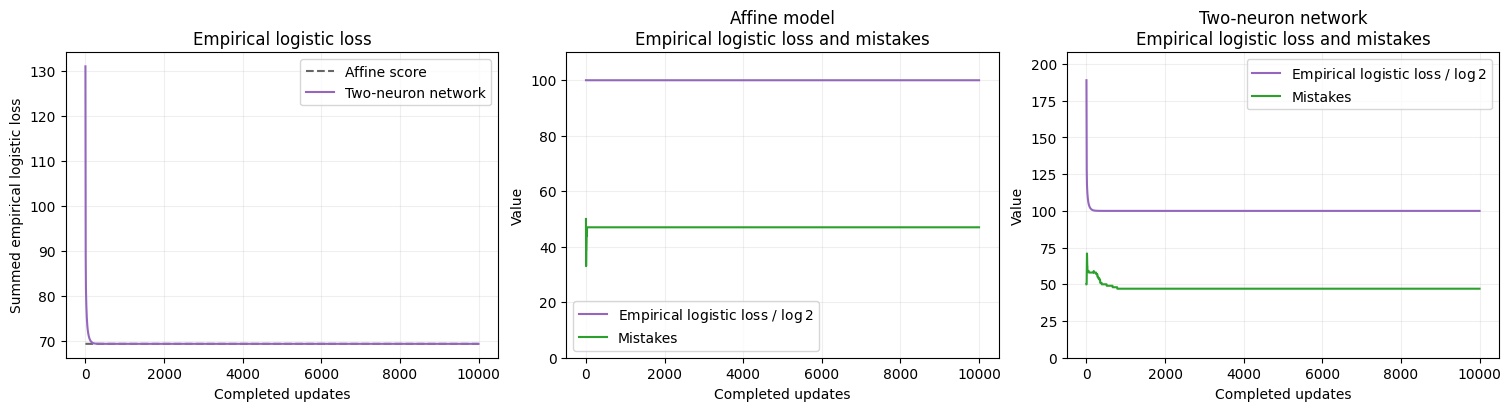

In [23]:
# Supplied: compare the affine classifier with the original two-neuron fit.
plot_first_comparison(affine_loss_history, affine_error_history,
                      narrow_loss_history, narrow_error_history)

### 4.2. Inspect the decision boundaries

A neural network's zero-score set need not be a single straight line.
The black boundary separates light blue class-0 regions from light orange
class-1 regions. At exactly zero, our classifier selects class 0.

**Exercise 7 — interpret the decision boundaries.**

Run the supplied cell to compare the affine fit with the original two-neuron
network after 1, 100 and 10,000 updates. How does the boundary change during
fitting? Does its final shape separate the four clouds successfully?

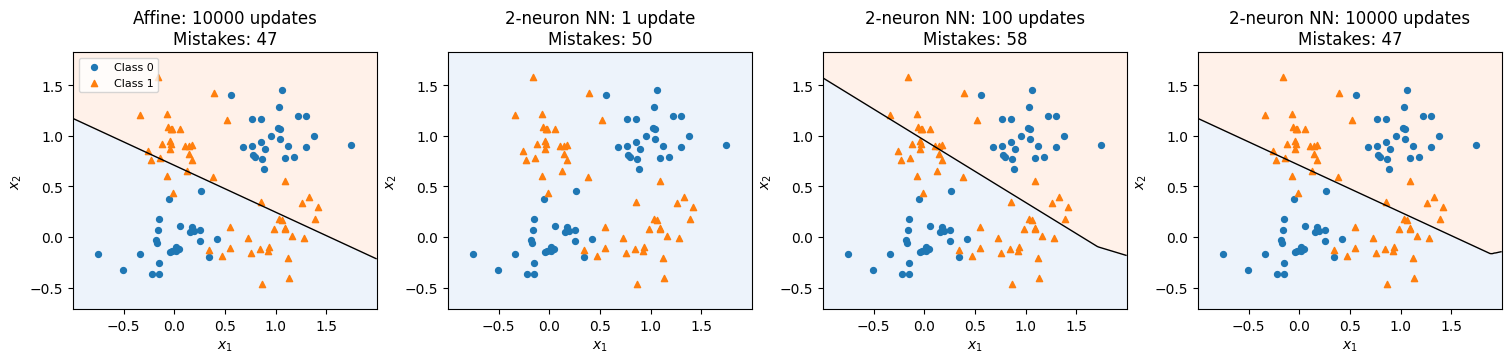

In [24]:
# Supplied: the affine fit and three stages of the original two-neuron fit.
plot_boundaries(
    [affine_grid_scores, narrow_boundary_scores[1],
     narrow_boundary_scores[100], narrow_boundary_scores[10000]],
    ['Affine: 10000 updates', '2-neuron NN: 1 update',
     '2-neuron NN: 100 updates', '2-neuron NN: 10000 updates'],
    [affine_error_history[-1], narrow_error_history[1],
     narrow_error_history[100], narrow_error_history[10000]])

## 5. Can we find a better two-neuron network?

Our fitted neural network has almost the same empirical logistic loss and
mistake count as the affine classifier, and a nearly straight boundary. Yet
this architecture solved XOR in the lecture. How does that constructed network
perform on our noisy observations?

### 5.1. Try the network constructed in the lecture

Our cloud centres are the lecture's four Boolean inputs. Use the same score:

$$s(\boldsymbol x)=\operatorname{ReLU}(x_1-x_2)
+\operatorname{ReLU}(x_2-x_1)-\frac12=|x_1-x_2|-\frac12.$$

**Exercise 8 — compare the ideal inputs with the noisy observations.**

1. Write `lecture_score(inputs)` for this score, returning one column of scores.
   Use slices such as `inputs[:, 0:1]` to preserve the column dimension.
2. Count its mistakes on the four supplied centres, using `centre_y`. Our helper
   `mistakes_from_scores` uses the 100 labels in `y`, so do not use it for the centres.
3. Evaluate the same score on the observed data `X`; now use `mistakes_from_scores`
   and `loss_from_scores` to report its mistakes and empirical logistic loss.
4. Explain why the lecture's exact classification of four inputs no longer
   guarantees correct labels for every observation in the clouds. Do your results
   show that this finite sample cannot be classified perfectly by any network?
5. Compare this empirical logistic loss with `narrow_loss_history[-1]`, the final
   value for your fitted two-neuron network. Both scores use the same architecture: can the
   parameters found by gradient descent be a global minimiser of its empirical logistic loss?

Use this separate function without changing the fitted `narrow_` parameters.

In [26]:
centre_X = t.tensor([[0.0, 0.0], [1.0, 1.0], [0.0, 1.0], [1.0, 0.0]])
centre_y = t.tensor([[0.0], [0.0], [1.0], [1.0]])

# YOUR CODE: define lecture_score and compare the centres with the noisy data.
def lecture_score(inputs):
  x = inputs[:, 0:1] - inputs[:, 1:2]
  return t.relu(x) + t.relu(-x) - 0.5

centre_scores = lecture_score(centre_X)
centre_mistakes = int(((centre_scores > 0).to(centre_y.dtype) != centre_y).sum().item())
noisy_scores = lecture_score(X)
print('Mistakes on the four centres:', centre_mistakes)
print('Mistakes on the noisy observations:', mistakes_from_scores(noisy_scores))
print('Empirical logistic loss on the noisy observations:', loss_from_scores(noisy_scores).item())

Mistakes on the four centres: 0
Mistakes on the noisy observations: 8
Empirical logistic loss on the noisy observations: 54.07107925415039


<details>
<summary>Show answer — ideal XOR versus noisy observations</summary>

The constructed score makes **0 mistakes on the centres** and **8 on the noisy
observations**, with empirical logistic loss about **54.071**. Some observations
move across its boundary while retaining their cloud's label. This explains
errors for this particular classifier; it does not prove that no network could
classify the finite sample perfectly.

The constructed score uses the same architecture and has lower empirical
logistic loss than our fitted network. Therefore, the fitted parameters are
not a global minimiser.

```python
centre_X = t.tensor([[0.0, 0.0], [1.0, 1.0], [0.0, 1.0], [1.0, 0.0]])
centre_y = t.tensor([[0.0], [0.0], [1.0], [1.0]])

def lecture_score(inputs):
    difference = inputs[:, 0:1] - inputs[:, 1:2]
    return t.relu(difference) + t.relu(-difference) - 0.5

centre_scores = lecture_score(centre_X)
centre_mistakes = int(((centre_scores > 0).to(centre_y.dtype) != centre_y).sum().item())
noisy_scores = lecture_score(X)
print('Mistakes on the four centres:', centre_mistakes)
print('Mistakes on the noisy observations:', mistakes_from_scores(noisy_scores))
print('Empirical logistic loss on the noisy observations:', loss_from_scores(noisy_scores).item())
```

</details>

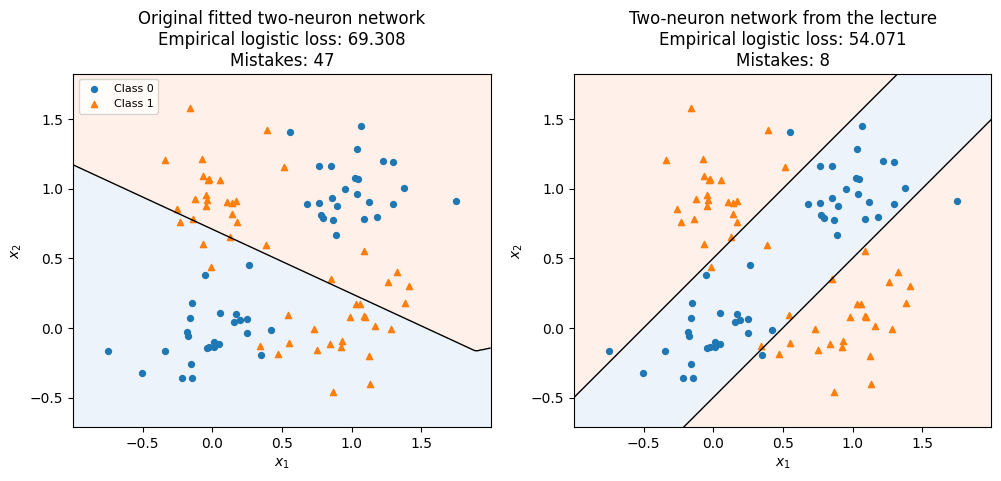

In [27]:
# Supplied: compare your fitted network with the network constructed in the lecture.
plot_lecture_comparison(narrow_grid_scores, narrow_loss_history[-1],
                        narrow_error_history[-1], lecture_score)

### Why did gradient descent miss these parameters?

Noise alone cannot explain our poor fit: we have found better parameters for
the same architecture. **Could gradient descent have become stuck near a
suboptimal local minimum?**

The empirical logistic loss is not convex in the network parameters. Gradient
descent follows local derivatives and can make little progress near a local
minimum or in a flat region.
The comparison alone does not tell us whether we reached a local minimum.

Let us try the lecture's first heuristic: **restart from different random
initialisations and keep the best fitted result**.

### 5.2. Try five initialisations and keep the best run

Run all five seeds **`[0, 1, 2, 3, 4]`**, keeping every result. These fixed seeds
make the experiment reproducible. The original seed was chosen to illustrate
a poor fit; this comparison reports all five attempts.

**Exercise 9 — compare five initialisations.**

**Part A: run the supplied experiment.** For each seed, the code draws new
parameters and repeats your fitting procedure with learning rate `0.001`
and 10,000 updates. The architecture, observations and labels stay fixed.

In [28]:
# Supplied: fix the five seeds and prepare separate records for every run.
restart_seeds = [0, 1, 2, 3, 4]
restart_loss_histories = {}
restart_error_histories = {}
restart_grid_scores_by_seed = {}
restart_parameters = {}
restart_input_features = 2
restart_hidden_features = 2
restart_output_features = 1

for seed in restart_seeds:
    t.manual_seed(seed)
    restart_b1 = t.randn(restart_hidden_features, requires_grad=True)
    restart_W1 = t.randn(restart_input_features, restart_hidden_features, requires_grad=True)
    restart_b2 = t.randn(restart_output_features, requires_grad=True)
    restart_W2 = t.randn(restart_hidden_features, restart_output_features, requires_grad=True)

    restart_learning_rate = 0.001
    restart_num_updates = 10000
    restart_run_boundary_scores = {}

    scores = net(X, restart_W1, restart_b1, restart_W2, restart_b2)
    restart_run_loss_history = [loss_from_scores(scores).item()]
    restart_run_error_history = [mistakes_from_scores(scores)]

    for step in range(1, restart_num_updates + 1):
        for parameter in (restart_b1, restart_W1, restart_b2, restart_W2):
            parameter.grad = None
        L = loss_from_scores(net(X, restart_W1, restart_b1, restart_W2, restart_b2))
        L.backward()

        with t.no_grad():
            restart_b1.add_(-restart_learning_rate * restart_b1.grad)
            restart_W1.add_(-restart_learning_rate * restart_W1.grad)
            restart_b2.add_(-restart_learning_rate * restart_b2.grad)
            restart_W2.add_(-restart_learning_rate * restart_W2.grad)

        scores = net(X, restart_W1, restart_b1, restart_W2, restart_b2)
        restart_run_loss_history.append(loss_from_scores(scores).item())
        restart_run_error_history.append(mistakes_from_scores(scores))

        # Supplied: record the boundary at these completed updates.
        if step in (1, 100, restart_num_updates):
            restart_run_boundary_scores[step] = save_boundary(net(X_grid, restart_W1, restart_b1, restart_W2, restart_b2))

    # Supplied: keep this completed run before drawing the next initialisation.
    restart_loss_histories[seed] = restart_run_loss_history
    restart_error_histories[seed] = restart_run_error_history
    restart_grid_scores_by_seed[seed] = restart_run_boundary_scores[restart_num_updates]
    restart_parameters[seed] = [restart_b1, restart_W1, restart_b2, restart_W2]

**Part B: keep the run with the lowest final empirical logistic loss.**
Run the next two supplied cells to select this model and display all five results.

In [29]:
# Supplied: select the run with the lowest final empirical logistic loss.
best_seed = restart_seeds[0]
for seed in restart_seeds[1:]:
    if restart_loss_histories[seed][-1] < restart_loss_histories[best_seed][-1]:
        best_seed = seed

print('Selected seed:', best_seed)
print('Final empirical logistic loss:', restart_loss_histories[best_seed][-1])
print('Mistakes:', restart_error_histories[best_seed][-1])

Selected seed: 1
Final empirical logistic loss: 24.280052185058594
Mistakes: 12


In [30]:
# Supplied: keep the selected model, not merely its reported empirical logistic loss.
best_parameters = restart_parameters[best_seed]
restart_b1 = best_parameters[0]
restart_W1 = best_parameters[1]
restart_b2 = best_parameters[2]
restart_W2 = best_parameters[3]
restart_loss_history = restart_loss_histories[best_seed]
restart_error_history = restart_error_histories[best_seed]
restart_grid_scores = restart_grid_scores_by_seed[best_seed]

print('Seed   Final empirical logistic loss   Mistakes')
for seed in restart_seeds:
    print(seed, restart_loss_histories[seed][-1], restart_error_histories[seed][-1])
print('Selected seed:', best_seed)

Seed   Final empirical logistic loss   Mistakes
0 52.711830139160156 28
1 24.280052185058594 12
2 39.353172302246094 27
3 24.28412628173828 12
4 36.11848449707031 25
Selected seed: 1


**Part C: compare every run.** Run the supplied figures showing the original
fit and all five restarts.

1. How much do final empirical logistic losses, mistake counts and boundaries
   vary across seeds? With the data, architecture and update rule fixed, what
   do these differences tell us about the role of initialisation?
2. Compare the selected run with the original fit and the lecture's constructed
   score. Do empirical logistic loss and mistake count rank these three models
   in the same order?

Write down your answers before opening the explanation.

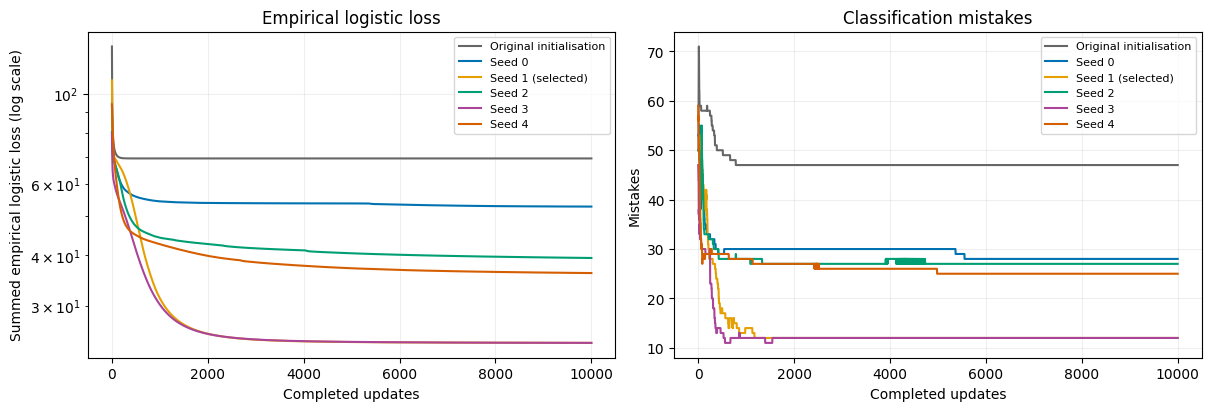

In [31]:
# Supplied: show the original run and all five restarts, keeping the architecture fixed.
plot_restart_curves(restart_seeds, restart_loss_histories, restart_error_histories,
                    narrow_loss_history, narrow_error_history, best_seed)

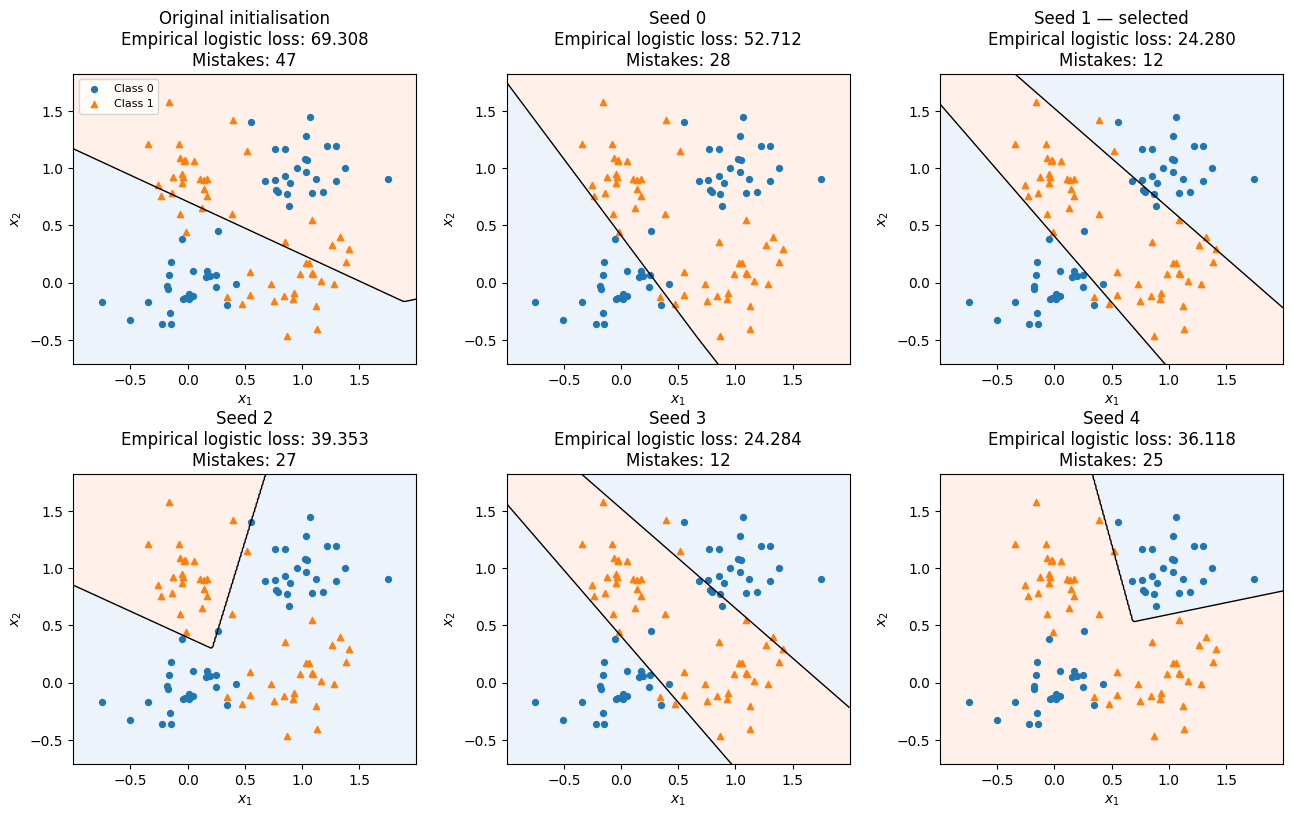

In [32]:
# Supplied: show every final boundary; identify the restart selected by final empirical logistic loss.
plot_restart_boundaries(
    restart_seeds, restart_grid_scores_by_seed, restart_loss_histories, restart_error_histories,
    narrow_grid_scores, narrow_loss_history[-1], narrow_error_history[-1], best_seed)

<details>
<summary>Show answer — comparing initialisations</summary>

Changing only the initialisation leads to substantially different fitted
boundaries and final empirical logistic losses. All five restarts improve
on the original fit.
The selection rule keeps **seed 1**, with empirical logistic loss **24.280** and
**12 mistakes**. Seed 3 finishes very close, with empirical logistic loss
**24.284** and the same mistake count.

The selected run's empirical logistic loss is lower than the lecture score's
**54.071**, although the selected run makes more mistakes (**12 versus 8**).
Empirical logistic loss accounts for prediction confidence; mistake count
uses only the sign of each score.

</details>

## 6. What changes with 100 hidden neurons?

Increase the hidden width from $d_1=2$ to $d_1=100$. The initialisation and fitting
calculations are the ones you have already implemented, now with hidden width
100. We pass this experiment's `wide_` parameters to the same `net` function.
**The complete code for this experiment is supplied.**

We use the same observations, five seeds **`[0, 1, 2, 3, 4]`**, learning rate
`0.001` and 10,000 updates per run. The same seed does not give differently shaped
parameter tensors identical values.

**Exercise 10 — investigate a wider network.**

**Part A: predict, then run.** Before running the supplied cell:

1. Predict the shapes of `wide_W1`, `wide_b1`, `wide_W2` and `wide_b2`,
   and the total number of scalar parameters.
2. Explain why we can use the same `net` function and gradient-descent update.

Run the complete code below to check your predictions and fit all five
initialisations.

In [33]:
# Supplied: use the same five seeds and keep separate results for the wider network.
wide_seeds = [0, 1, 2, 3, 4]
wide_loss_histories = {}
wide_error_histories = {}
wide_grid_scores_by_seed = {}
wide_parameters = {}
wide_input_features = 2 # 2,100 1,100 100,1 1,1
wide_hidden_features = 100
wide_output_features = 1

for seed in wide_seeds:
    t.manual_seed(seed)
    wide_b1 = t.randn(wide_hidden_features, requires_grad=True)
    wide_W1 = t.randn(wide_input_features, wide_hidden_features, requires_grad=True)
    wide_b2 = t.randn(wide_output_features, requires_grad=True)
    wide_W2 = t.randn(wide_hidden_features, wide_output_features, requires_grad=True)
    print('Seed:', seed)
    print('wide_W1:', wide_W1.shape, 'wide_b1:', wide_b1.shape)
    print('wide_W2:', wide_W2.shape, 'wide_b2:', wide_b2.shape)
    print('Scalar parameters:', wide_W1.numel() + wide_b1.numel() + wide_W2.numel() + wide_b2.numel())

    wide_learning_rate = 0.001
    wide_num_updates = 10000
    wide_run_boundary_scores = {}

    scores = net(X, wide_W1, wide_b1, wide_W2, wide_b2)
    wide_run_loss_history = [loss_from_scores(scores).item()]
    wide_run_error_history = [mistakes_from_scores(scores)]

    for step in range(1, wide_num_updates + 1):
        for parameter in (wide_b1, wide_W1, wide_b2, wide_W2):
            parameter.grad = None
        L = loss_from_scores(net(X, wide_W1, wide_b1, wide_W2, wide_b2))
        L.backward()

        with t.no_grad():
            wide_b1.add_(-wide_learning_rate * wide_b1.grad)
            wide_W1.add_(-wide_learning_rate * wide_W1.grad)
            wide_b2.add_(-wide_learning_rate * wide_b2.grad)
            wide_W2.add_(-wide_learning_rate * wide_W2.grad)

        scores = net(X, wide_W1, wide_b1, wide_W2, wide_b2)
        wide_run_loss_history.append(loss_from_scores(scores).item())
        wide_run_error_history.append(mistakes_from_scores(scores))

        # Supplied: record the boundary at these completed updates.
        if step in (1, 100, wide_num_updates):
            wide_run_boundary_scores[step] = save_boundary(net(X_grid, wide_W1, wide_b1, wide_W2, wide_b2))

    # Supplied: retain this completed 100-neuron run.
    wide_loss_histories[seed] = wide_run_loss_history
    wide_error_histories[seed] = wide_run_error_history
    wide_grid_scores_by_seed[seed] = wide_run_boundary_scores[wide_num_updates]
    wide_parameters[seed] = [wide_b1, wide_W1, wide_b2, wide_W2]

Seed: 0
wide_W1: torch.Size([2, 100]) wide_b1: torch.Size([100])
wide_W2: torch.Size([100, 1]) wide_b2: torch.Size([1])
Scalar parameters: 401
Seed: 1
wide_W1: torch.Size([2, 100]) wide_b1: torch.Size([100])
wide_W2: torch.Size([100, 1]) wide_b2: torch.Size([1])
Scalar parameters: 401
Seed: 2
wide_W1: torch.Size([2, 100]) wide_b1: torch.Size([100])
wide_W2: torch.Size([100, 1]) wide_b2: torch.Size([1])
Scalar parameters: 401
Seed: 3
wide_W1: torch.Size([2, 100]) wide_b1: torch.Size([100])
wide_W2: torch.Size([100, 1]) wide_b2: torch.Size([1])
Scalar parameters: 401
Seed: 4
wide_W1: torch.Size([2, 100]) wide_b1: torch.Size([100])
wide_W2: torch.Size([100, 1]) wide_b2: torch.Size([1])
Scalar parameters: 401


<details>
<summary>Show answer — tensor shapes and reuse of the same calculations</summary>

The shapes are `wide_W1`: `(2, 100)`, `wide_b1`: `(100,)`, `wide_W2`: `(100, 1)` and `wide_b2`: `(1,)`.
There are $2\times100+100+100\times1+1=401$ scalar parameters.

The same matrix products now produce 100 hidden activations per observation
and still one output score. Each gradient has the same shape as its parameter,
so the same entry-by-entry update applies to the wider tensors.

</details>

**Part B: select by final empirical logistic loss.** Run the next two supplied
cells to keep the best of the five runs and display their results, as in Exercise 9.

In [45]:
# Supplied: select the run with the lowest final empirical logistic loss.
wide_best_seed = wide_seeds[0]
for seed in wide_seeds[1:]:
    if wide_loss_histories[seed][-1] < wide_loss_histories[wide_best_seed][-1]:
        wide_best_seed = seed

print('Selected seed:', wide_best_seed)
print('Final empirical logistic loss:', wide_loss_histories[wide_best_seed][-1])
print('Mistakes:', wide_error_histories[wide_best_seed][-1])

Selected seed: 1
Final empirical logistic loss: 3.932190179824829
Mistakes: 1


In [46]:
# Supplied: check all five fits and restore the selected 100-neuron model.
for seed in wide_seeds:
    assert seed in wide_loss_histories, 'Complete all five 100-neuron fits before saving the selected run.'
    assert len(wide_loss_histories[seed]) == len(wide_error_histories[seed]) == 10001
    assert wide_parameters[seed][1].shape == (2, 100)
wide_best_parameters = wide_parameters[wide_best_seed]
wide_b1 = wide_best_parameters[0]
wide_W1 = wide_best_parameters[1]
wide_b2 = wide_best_parameters[2]
wide_W2 = wide_best_parameters[3]
wide_loss_history = wide_loss_histories[wide_best_seed]
wide_error_history = wide_error_histories[wide_best_seed]
wide_grid_scores = wide_grid_scores_by_seed[wide_best_seed]

print('Seed   Final empirical logistic loss   Mistakes')
for seed in wide_seeds:
    print(seed, wide_loss_histories[seed][-1], wide_error_histories[seed][-1])
print('Selected seed:', wide_best_seed)

Seed   Final empirical logistic loss   Mistakes
0 4.38054895401001 1
1 3.932190179824829 1
2 4.3576884269714355 1
3 4.262890815734863 1
4 4.212905406951904 1
Selected seed: 1


**Part C: inspect all five runs.** Run the supplied curves and boundary panels.
The middle curve panel enlarges updates 100–10000 to show later changes in
empirical logistic loss.

How much do final empirical logistic losses, mistake counts and boundaries vary
across seeds? Compare this variation with the two-neuron runs. Do all five wider
networks separate the four clouds reasonably well?

Write down your interpretation before opening the explanation.

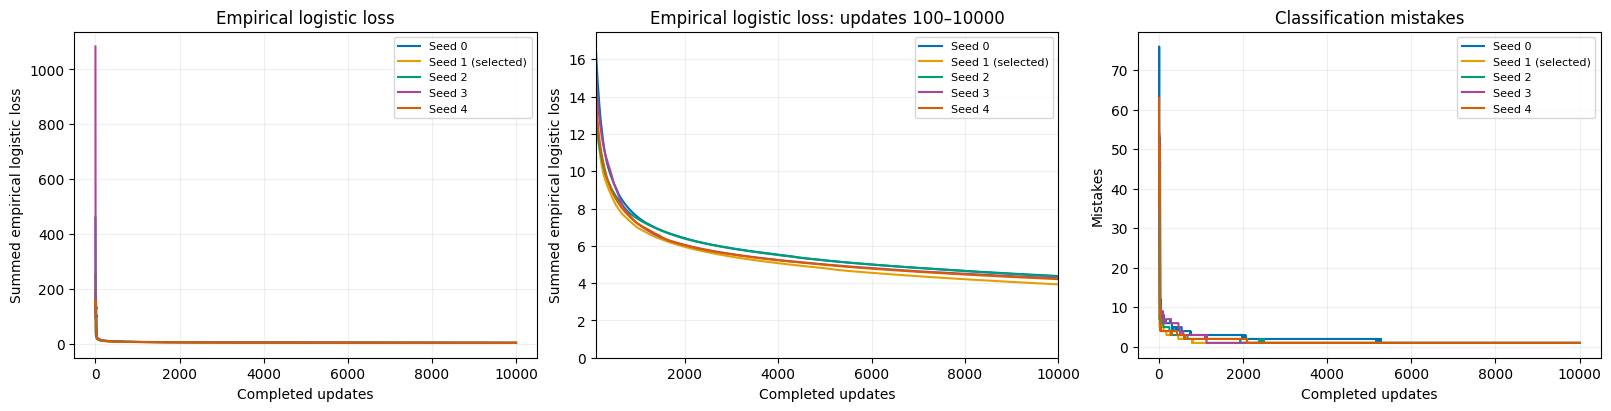

In [37]:
# Supplied: show all five 100-neuron fits with solid curves and one colour per seed.
plot_wide_curves(wide_seeds, wide_loss_histories, wide_error_histories, wide_best_seed)

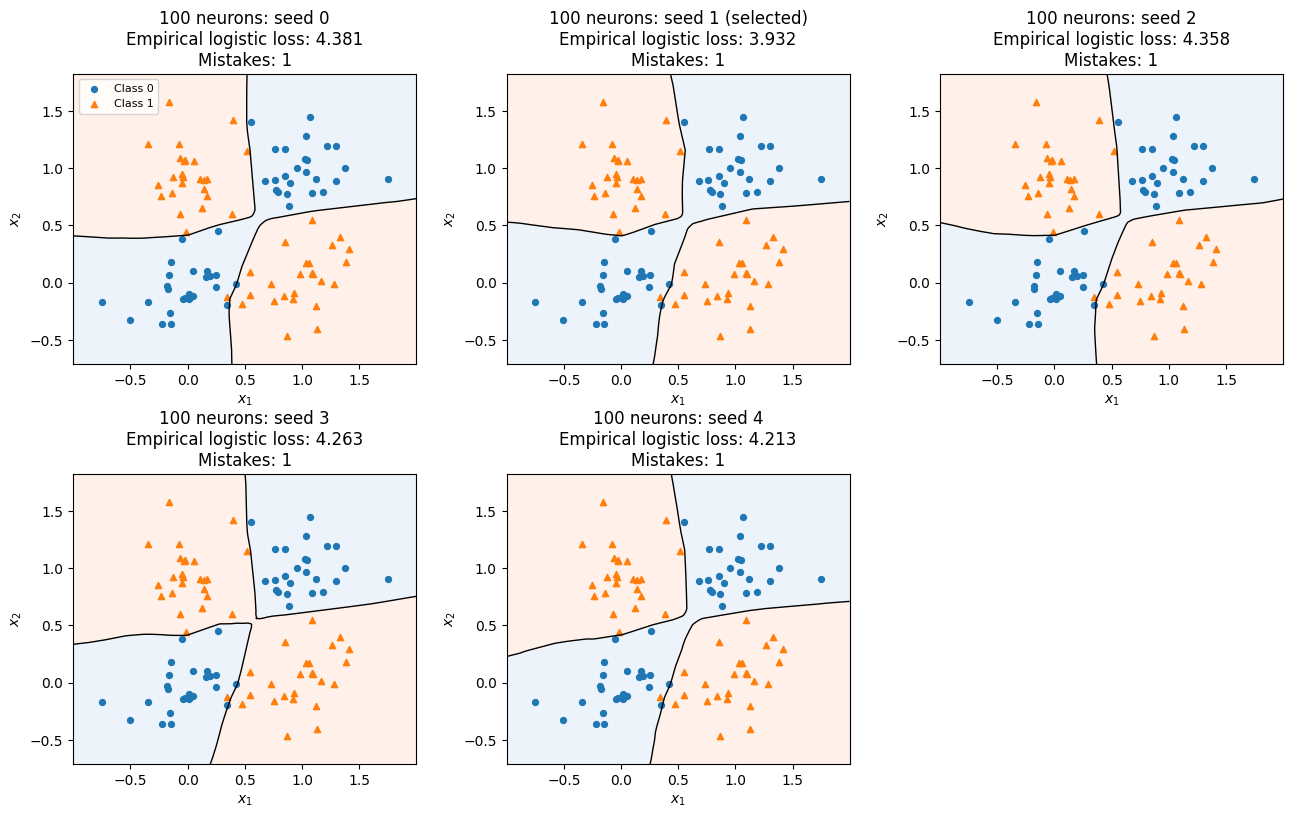

In [38]:
# Supplied: show every final 100-neuron boundary and identify the selected run.
plot_wide_boundaries(wide_seeds, wide_grid_scores_by_seed,
                     wide_loss_histories, wide_error_histories, wide_best_seed)

<details>
<summary>Show answer — the five wider fits</summary>

All five 100-neuron runs finish with empirical logistic losses between
**3.932 and 4.381** and **one mistake each**. Seed **1** has the lowest final
empirical logistic loss and is retained. Their exact boundaries differ even
though their mistake counts agree.

The two-neuron runs vary much more: empirical logistic losses **24.280–52.712**
and **12–28 mistakes**. Here, widening improves the fit across all five seeds.

</details>

**Exercise 11 — compare the two widths.**

**Part A: curves.** Run the supplied cell to compare the original two-neuron
fit, the best of its five restarts, and the best of the five 100-neuron runs.
Compare both empirical logistic losses and mistake counts.

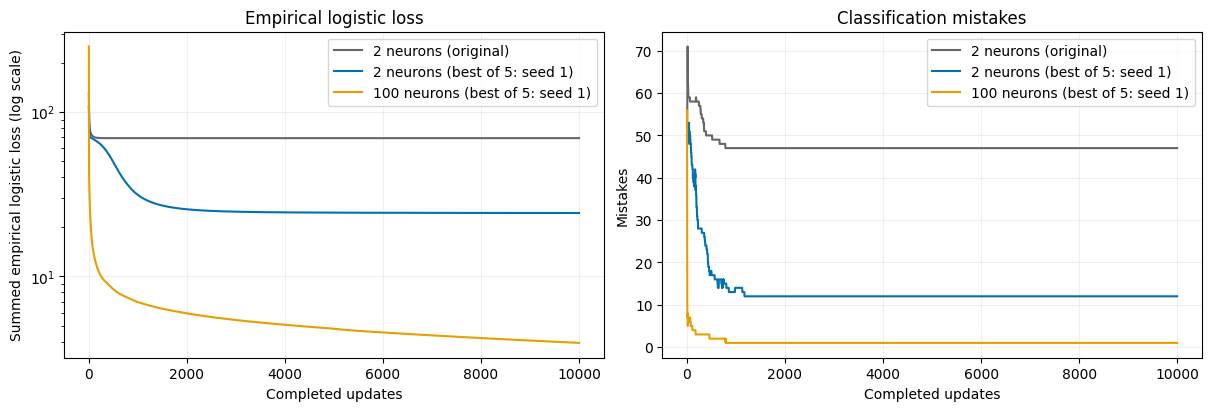

In [39]:
# Supplied: compare the original fit with the best of five runs at each width.
plot_network_curves(
    ['2 neurons (original)', f'2 neurons (best of 5: seed {best_seed})',
     f'100 neurons (best of 5: seed {wide_best_seed})'],
    [narrow_loss_history, restart_loss_history, wide_loss_history],
    [narrow_error_history, restart_error_history, wide_error_history],
    colors=['#666666', '#0072B2', '#E69F00'])

**Part B: boundaries.** Run the supplied cell to compare the affine classifier,
the original two-neuron fit, its best restart, and the best of the five wider
runs.

Which has the smaller empirical logistic loss and fewer mistakes? How do their boundaries differ?
Does widening guarantee a better fit for every initialisation, or better
predictions on unseen observations?

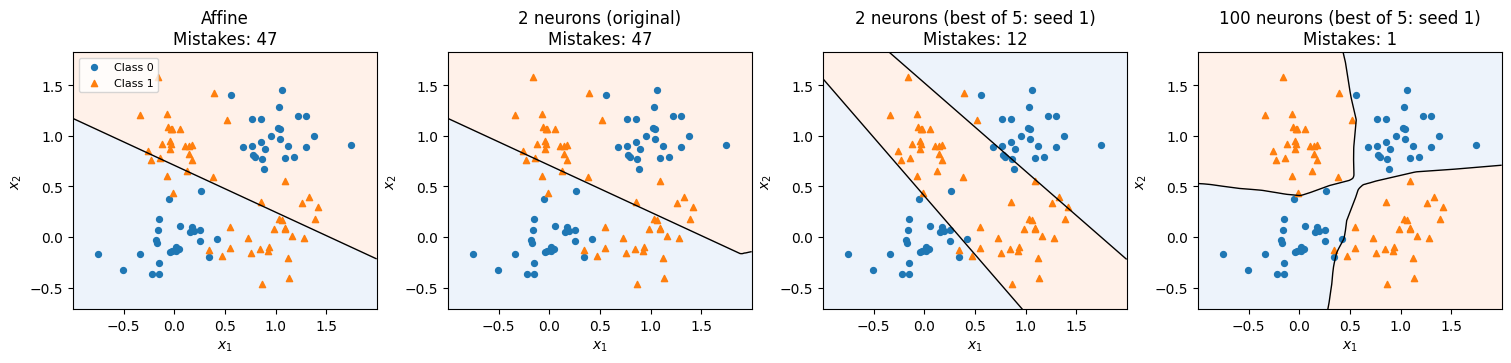

In [40]:
# Supplied: compare the final affine and neural-network boundaries.
plot_boundaries(
    [affine_grid_scores, narrow_grid_scores, restart_grid_scores, wide_grid_scores],
    ['Affine', '2 neurons (original)', f'2 neurons (best of 5: seed {best_seed})',
     f'100 neurons (best of 5: seed {wide_best_seed})'],
    [affine_error_history[-1], narrow_error_history[-1], restart_error_history[-1], wide_error_history[-1]])

<details>
<summary>Show answer — comparing widths</summary>

Restarting improves the two-neuron fit. The wider networks achieve lower
empirical logistic losses and fewer mistakes than all five two-neuron runs.

Both searches use five runs of 10,000 updates. The wider network has 401
parameters rather than 9, so its updates require more calculations. These
results do not guarantee improvement for every initialisation, a global
minimum, or better predictions on unseen observations.

</details>

## 7. Build the network with hidden widths 5 and 7

We now use the lecture's architecture with **two hidden layers**, of 5 and 7
neurons, and one scalar output: $(d_0,d_1,d_2,d_3)=(2,5,7,1)$.
You will implement its parameters, score function and gradient calculation.
The fitting and plotting code is supplied.

For the full dataset $\boldsymbol X$, the calculation is
(each bias is added to every row):

$$
\begin{aligned}
\boldsymbol\Phi_1
  &=\operatorname{\mathbf{ReLU}}(\boldsymbol X\boldsymbol W_1+\boldsymbol b_1),\\
\boldsymbol\Phi_2
  &=\operatorname{\mathbf{ReLU}}(\boldsymbol\Phi_1\boldsymbol W_2+\boldsymbol b_2),\\
f_{\boldsymbol\theta}(\boldsymbol X)
  &=\boldsymbol\Phi_2\boldsymbol W_3+\boldsymbol b_3.
\end{aligned}
$$

### 7.1. Parameters

**Exercise 12 — translate the architecture into tensors.**

1. Determine the shapes of the three weight matrices and three bias vectors
   from the matrix products. How many scalar parameters are there altogether?
2. Use the supplied dimension variables and `t.randn(..., requires_grad=True)`
   to create `deep_b1`, `deep_W1`, `deep_b2`, `deep_W2`, `deep_b3`, `deep_W3`,
   in that order. As before, each bias is a one-dimensional tensor.
3. Print their shapes and check your parameter count using `.numel()`.

We use seed 0, the first seed in the previous experiments.

In [49]:
t.manual_seed(0)  # Supplied: the first seed in our earlier five-seed experiments.
deep_input_features = 2
deep_hidden_1 = 5
deep_hidden_2 = 7
deep_output_features = 1

# YOUR CODE: create the six parameter tensors, print their shapes and count their entries.
deep_b1 = t.randn(deep_hidden_1, requires_grad=True)
deep_W1 = t.randn(deep_input_features, deep_hidden_1, requires_grad=True)
deep_b2 = t.randn(deep_hidden_2, requires_grad=True)
deep_W2 = t.randn(deep_hidden_1, deep_hidden_2, requires_grad=True)
deep_b3 = t.randn(deep_output_features, requires_grad=True)
deep_W3 = t.randn(deep_hidden_2, deep_output_features, requires_grad=True)
print('W1:', deep_W1.shape, 'b1:', deep_b1.shape)
print('W2:', deep_W2.shape, 'b2:', deep_b2.shape)
print('W3:', deep_W3.shape, 'b3:', deep_b3.shape)
print('Scalar parameters:', deep_W1.numel() + deep_b1.numel()
      + deep_W2.numel() + deep_b2.numel() + deep_W3.numel() + deep_b3.numel())

W1: torch.Size([2, 5]) b1: torch.Size([5])
W2: torch.Size([5, 7]) b2: torch.Size([7])
W3: torch.Size([7, 1]) b3: torch.Size([1])
Scalar parameters: 65


<details>
<summary>Show answer — six parameter tensors</summary>

The weight shapes are `(2, 5)`, `(5, 7)` and `(7, 1)`; the bias shapes are
`(5,)`, `(7,)` and `(1,)`. The total is
$2\times5+5+5\times7+7+7\times1+1=65$ scalar parameters.

```python
t.manual_seed(0)  # Supplied: the first seed in our earlier five-seed experiments.
deep_input_features = 2
deep_hidden_1 = 5
deep_hidden_2 = 7
deep_output_features = 1

deep_b1 = t.randn(deep_hidden_1, requires_grad=True)
deep_W1 = t.randn(deep_input_features, deep_hidden_1, requires_grad=True)
deep_b2 = t.randn(deep_hidden_2, requires_grad=True)
deep_W2 = t.randn(deep_hidden_1, deep_hidden_2, requires_grad=True)
deep_b3 = t.randn(deep_output_features, requires_grad=True)
deep_W3 = t.randn(deep_hidden_2, deep_output_features, requires_grad=True)
print('W1:', deep_W1.shape, 'b1:', deep_b1.shape)
print('W2:', deep_W2.shape, 'b2:', deep_b2.shape)
print('W3:', deep_W3.shape, 'b3:', deep_b3.shape)
print('Scalar parameters:', deep_W1.numel() + deep_b1.numel()
      + deep_W2.numel() + deep_b2.numel() + deep_W3.numel() + deep_b3.numel())
```

</details>

### 7.2. Score function

**Exercise 13 — write `deep_net(inputs, W1, b1, W2, b2, W3, b3)`.**
Translate the three equations into a function receiving the six parameter
tensors. Use its local argument names in the formulas. Call it with
`deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3)`
to evaluate the parameters from Exercise 12. Apply `t.relu` after each
hidden affine calculation; the final affine calculation returns scores directly.

Predict the shapes of both hidden-activation matrices and the output for
the full dataset `X`. Then run the supplied check.

In [ ]:
# YOUR CODE: define deep_net(inputs, W1, b1, W2, b2, W3, b3).
def deep_net(inputs, W1, b1, W2, b2, W3, b3):
  print("d")


deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3)

<details>
<summary>Show answer — compose two hidden layers</summary>

For `X`, the first hidden activations have shape `(N, 5)`, the second `(N, 7)`,
and the scores `(N, 1)`.

```python
def deep_net(inputs, W1, b1, W2, b2, W3, b3):
    a1 = inputs @ W1 + b1
    phi1 = t.relu(a1)
    a2 = phi1 @ W2 + b2
    phi2 = t.relu(a2)
    return phi2 @ W3 + b3
```

</details>

In [ ]:
# Supplied: check the output shape for the full dataset.
assert deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3).shape == (N, 1)

### 7.3. Gradients

**Exercise 14 — differentiate the new network's empirical logistic loss.**
After the supplied clearing code, evaluate `deep_net` on `X`, calculate its
empirical logistic loss with `loss_from_scores`, and differentiate it as in
Exercise 4. Print each parameter's shape and its gradient's shape.

How many calls to `backward()` are needed to obtain the gradients of all six
parameter tensors?

In [ ]:
# Supplied: clear any gradients left by an earlier execution.
for parameter in (deep_b1, deep_W1, deep_b2, deep_W2, deep_b3, deep_W3):
    parameter.grad = None

# YOUR CODE: calculate the empirical logistic loss, differentiate it and print all six gradient shapes.
raise NotImplementedError("Replace this line with your code.")

<details>
<summary>Show answer — one differentiation for all six tensors</summary>

One `L.backward()` call calculates derivatives with respect to all six parameter
tensors used in the calculation and stores them in their `.grad` attributes.

```python
# Supplied: clear any gradients left by an earlier execution.
for parameter in (deep_b1, deep_W1, deep_b2, deep_W2, deep_b3, deep_W3):
    parameter.grad = None

L = loss_from_scores(deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3))
L.backward()
print('W1:', deep_W1.shape, deep_W1.grad.shape)
print('b1:', deep_b1.shape, deep_b1.grad.shape)
print('W2:', deep_W2.shape, deep_W2.grad.shape)
print('b2:', deep_b2.shape, deep_b2.grad.shape)
print('W3:', deep_W3.shape, deep_W3.grad.shape)
print('b3:', deep_b3.shape, deep_b3.grad.shape)
```

</details>

### 7.4. Fit and compare — supplied code

Run the complete fitting cell below. It uses the same data, empirical logistic
loss, learning rate `0.001` and 10,000 updates as the earlier networks. The update
now includes six parameter tensors.

To repeat the fit from its initial values, rerun Exercise 12 first. Running
only the fitting cell continues from the current parameters.

In [ ]:
# Supplied: fit the network with two hidden layers.
deep_learning_rate = 0.001
deep_num_updates = 10000
deep_boundary_scores = {}

scores = deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3)
deep_loss_history = [loss_from_scores(scores).item()]
deep_error_history = [mistakes_from_scores(scores)]

for step in range(1, deep_num_updates + 1):
    for parameter in (deep_b1, deep_W1, deep_b2, deep_W2, deep_b3, deep_W3):
        parameter.grad = None
    L = loss_from_scores(deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3))
    L.backward()

    with t.no_grad():
        deep_b1.add_(-deep_learning_rate * deep_b1.grad)
        deep_W1.add_(-deep_learning_rate * deep_W1.grad)
        deep_b2.add_(-deep_learning_rate * deep_b2.grad)
        deep_W2.add_(-deep_learning_rate * deep_W2.grad)
        deep_b3.add_(-deep_learning_rate * deep_b3.grad)
        deep_W3.add_(-deep_learning_rate * deep_W3.grad)

    scores = deep_net(X, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3)
    deep_loss_history.append(loss_from_scores(scores).item())
    deep_error_history.append(mistakes_from_scores(scores))
    if step in (1, 100, deep_num_updates):
        deep_boundary_scores[step] = save_boundary(deep_net(X_grid, deep_W1, deep_b1, deep_W2, deep_b2, deep_W3, deep_b3))

deep_grid_scores = deep_boundary_scores[deep_num_updates]
print('Updates   Empirical logistic loss   Mistakes')
for step in (0, 1, 100, deep_num_updates):
    print(step, deep_loss_history[step], deep_error_history[step])

Run the supplied plots to compare **seed 0 at all three architectures**:
2 hidden neurons, 100 hidden neurons, and hidden layers of 5 and 7 neurons.
This comparison uses seed 0 rather than the best of five. Each fit uses
10,000 updates.

1. How do the empirical logistic loss and mistake count change during fitting
   for the 5–7 network? Compare its final results and boundary with the other two.
2. Which parts of your score function changed when adding the second hidden
   layer? Which parts of the empirical logistic loss and differentiation code
   stayed the same?
3. Does this experiment isolate the effect of adding a hidden layer?
   Explain what else differs between the architectures.

Write down your interpretation before opening the explanation.

In [ ]:
# Supplied: compare the three architectures using seed 0 in each case.
plot_network_curves(
    ['2 neurons: seed 0', '100 neurons: seed 0', '5–7 hidden neurons: seed 0'],
    [restart_loss_histories[0], wide_loss_histories[0], deep_loss_history],
    [restart_error_histories[0], wide_error_histories[0], deep_error_history],
    colors=['#0072B2', '#E69F00', '#009E73'])

In [ ]:
# Supplied: show the final boundary and mistake count of each seed-0 run.
plot_boundaries(
    [restart_grid_scores_by_seed[0], wide_grid_scores_by_seed[0], deep_grid_scores],
    ['2 neurons: seed 0', '100 neurons: seed 0', '5–7 hidden neurons: seed 0'],
    [restart_error_histories[0][-1], wide_error_histories[0][-1], deep_error_history[-1]])

<details>
<summary>Show answer — interpreting the two-hidden-layer experiment</summary>

With seed 0, the 5–7 network's empirical logistic loss falls from approximately
95.483 to **2.650**, while its mistake count changes from 33 to **1**. The
two-neuron run ends at **52.712** with **28 mistakes**; the 100-neuron run ends
at **4.381** with **one mistake**. The 5–7 network has a lower empirical logistic
loss than the 100-neuron run, although their final mistake counts agree.

The score function now composes two hidden affine transformations with ReLU
before the final affine output. It still returns one score for each observation,
so the empirical logistic loss and the single call to `backward()` are unchanged.
The same gradient-descent rule updates six tensors instead of four.

The architectures have 9, 401 and 65 parameters, respectively. Their widths and
initial parameter values differ as well as their number of hidden layers.

</details>